# CyberIntel: Automated OSINT-Based Cyber Threat Intelligence and Risk Analysis

**Subject:** Python for Data Science (Problem Based Learning activity)
**Team 33:** Trivedi Harshil (251373107009), Muneer Khaled, Neer Kapadia

## What this project does
Open Source Intelligence (OSINT) means using information that is publicly available to understand threats.
Here we use the **CISA Known Exploited Vulnerabilities (KEV) catalog**, an official public list of software
flaws that attackers are *actively exploiting in the real world*.

The notebook:
1. loads and cleans the public catalog,
2. explores it (what is being attacked, by whom, over time),
3. extracts threat signals from the public descriptions (attack type, exposed device hints),
4. trains machine-learning models to predict which exploited vulnerabilities are **linked to ransomware campaigns**,
5. turns the result into a **0-100 risk score and a risk tier** for every vulnerability, and
6. lets you analyse a *new* vulnerability description.

**Ethics note:** all data is public and is about software products and organisations. The project does not collect
or profile private individuals.

**How to run:** put `known_exploited_vulnerabilities.csv` in the same folder as this notebook, then choose
*Kernel > Restart & Run All*. Needs: pandas, numpy, matplotlib, scikit-learn.

## Step 0: Setup

In [1]:
import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

DATA_FILE = Path("known_exploited_vulnerabilities.csv")
OUT = Path("outputs"); (OUT / "figures").mkdir(parents=True, exist_ok=True)
SEED = 42

# Chart style: one blue for the normal case, one orange for the ransomware-linked case
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#222222", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#999999",
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "figure.dpi": 100, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True})

def finish(fig, name):
    """Save a chart into outputs/figures and show it."""
    fig.tight_layout()
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "Download the CISA KEV catalog as CSV (cisa.gov/known-exploited-vulnerabilities-catalog) "
        f"and save it next to this notebook as '{DATA_FILE}'.")
print("Setup complete. Data file found:", DATA_FILE)

Setup complete. Data file found: known_exploited_vulnerabilities.csv


## Step 1: Load the public data
Each row is one vulnerability that CISA has confirmed is being exploited. The column
`knownRansomwareCampaignUse` says whether it is known to be used in ransomware attacks. That column is what
our model will learn to predict.

In [2]:
raw = pd.read_csv(DATA_FILE)
raw.columns = raw.columns.str.strip()
need = ["cveID", "vendorProject", "product", "vulnerabilityName", "dateAdded", "shortDescription",
        "dueDate", "knownRansomwareCampaignUse", "cwes"]
missing = [c for c in need if c not in raw.columns]
assert not missing, f"These expected columns are missing from the CSV: {missing}"
print("Rows:", len(raw), "| Columns:", len(raw.columns))
raw.head()

Rows: 1733 | Columns: 12


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes
0,CVE-2026-102490,Zammad GmbH,Zammad,Zammad GmbH Zammad Improper Privilege Management Vulnerability,2026-10-02,Zammad GmbH Zammad contains an improper privilege management vulne...,"Apply mitigations in accordance with vendor instructions, ensuring...",2026-10-05,Unknown,Yes,https://zammad.com/en/product/releases/ ; https://community.zammad...,CWE-269
1,CVE-2026-102489,Zammad GmbH,Zammad,Zammad GmbH Zammad Session Fixation Vulnerability,2026-10-02,Zammad GmbH Zammad contains a session fixation vulnerability that ...,"Apply mitigations in accordance with vendor instructions, ensuring...",2026-10-05,Unknown,Yes,https://zammad.com/en/product/releases/ ; https://community.zammad...,CWE-384
2,CVE-2026-104286,Fortinet,FortiMail,Fortinet FortiMail Path Traversal Vulnerability,2026-10-01,Fortinet FortiMail contains a path traversal and an improper neutr...,"Apply mitigations in accordance with vendor instructions, ensuring...",2026-10-04,Unknown,Yes,https://fortiguard.fortinet.com/psirt/FG-IR-26-175 ; ; BOD 26-04: ...,"CWE-22, CWE-158"
3,CVE-2026-76504,Cisco,Catalyst SD-WAN Manager,Cisco Catalyst SD-WAN Manager Hex Encoding Vulnerability,2026-09-30,Cisco Catalyst SD-WAN Manager contains a hex encoding vulnerabilit...,"Apply mitigations in accordance with vendor instructions, ensuring...",2026-10-03,Unknown,Yes,https://sec.cloudapps.cisco.com/security/center/content/CiscoSecur...,CWE-177
4,CVE-2026-86950,Apple,Multiple Products,Apple Multiple Products Out-of-Bounds Write Vulnerability,2026-09-29,"Apple iOS, macOS, and iPadOS contain an out-of-bounds write vulner...","Apply mitigations in accordance with vendor instructions, ensuring...",2026-10-02,Unknown,Yes,https://support.apple.com/en-us/149226 ; https://support.apple.com...,CWE-787


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   cveID                       1733 non-null   str  
 1   vendorProject               1733 non-null   str  
 2   product                     1733 non-null   str  
 3   vulnerabilityName           1733 non-null   str  
 4   dateAdded                   1733 non-null   str  
 5   shortDescription            1733 non-null   str  
 6   requiredAction              1733 non-null   str  
 7   dueDate                     1733 non-null   str  
 8   knownRansomwareCampaignUse  1733 non-null   str  
 9   forensicTriage              1733 non-null   str  
 10  notes                       1733 non-null   str  
 11  cwes                        1558 non-null   str  
dtypes: str(12)
memory usage: 162.6 KB


## Step 2: Clean the data and build basic features
- Convert dates to real dates and pull out year and month.
- `days_to_remediate` = days CISA gives organisations to fix the flaw (due date minus date added).
- `cwes` lists the weakness type (CWE = Common Weakness Enumeration). We keep the first one and count them.
- The **target** `ransomware` is 1 if the flaw is known to be used by ransomware groups, otherwise 0.

In [4]:
df = raw.copy()
for c in ["vendorProject", "product", "vulnerabilityName", "shortDescription", "cwes", "knownRansomwareCampaignUse"]:
    df[c] = df[c].fillna("").astype(str).str.strip()

df["dateAdded"] = pd.to_datetime(df["dateAdded"], errors="coerce")
df["dueDate"] = pd.to_datetime(df["dueDate"], errors="coerce")
df = df.dropna(subset=["dateAdded"]).drop_duplicates(subset="cveID").reset_index(drop=True)

df["year_added"] = df["dateAdded"].dt.year
df["month_added"] = df["dateAdded"].dt.month
df["days_to_remediate"] = (df["dueDate"] - df["dateAdded"]).dt.days
df["days_to_remediate"] = df["days_to_remediate"].fillna(df["days_to_remediate"].median())

cwe_lists = df["cwes"].apply(lambda s: re.findall(r"(?:NVD-)?CWE-[A-Za-z0-9]+", s))
df["primary_cwe"] = cwe_lists.apply(lambda l: l[0] if l else "Unknown")
df["n_cwes"] = cwe_lists.apply(len)

df["text"] = (df["vulnerabilityName"] + ". " + df["shortDescription"]).str.strip()
df["ransomware"] = (df["knownRansomwareCampaignUse"].str.lower() == "known").astype(int)

print(f"{len(df)} vulnerabilities, added between {df['dateAdded'].min().date()} and {df['dateAdded'].max().date()}")
print(f"Linked to ransomware: {df['ransomware'].sum()} ({df['ransomware'].mean():.1%})")
df[["cveID", "vendorProject", "product", "dateAdded", "primary_cwe", "days_to_remediate", "ransomware"]].head()

1733 vulnerabilities, added between 2021-11-03 and 2026-10-02
Linked to ransomware: 361 (20.8%)


,cveID,vendorProject,product,dateAdded,primary_cwe,days_to_remediate,ransomware
0,CVE-2026-102490,Zammad GmbH,Zammad,2026-10-02,CWE-269,3,0
1,CVE-2026-102489,Zammad GmbH,Zammad,2026-10-02,CWE-384,3,0
2,CVE-2026-104286,Fortinet,FortiMail,2026-10-01,CWE-22,3,0
3,CVE-2026-76504,Cisco,Catalyst SD-WAN Manager,2026-09-30,CWE-177,3,0
4,CVE-2026-86950,Apple,Multiple Products,2026-09-29,CWE-787,3,0


## Step 3: Explore the threat landscape
Before any machine learning, we look at the data to see what stands out.

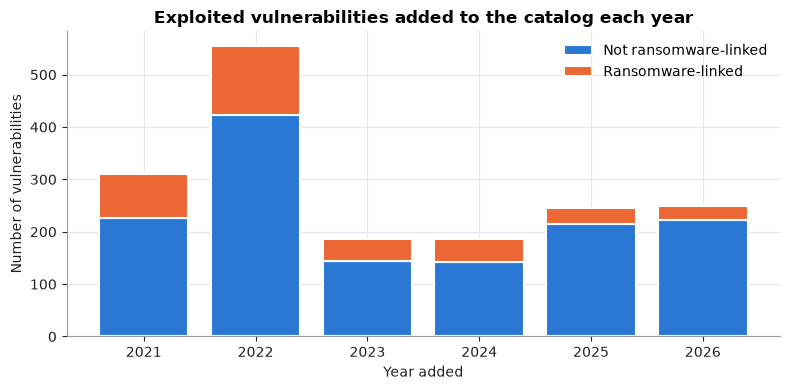

ransomware,Not ransomware-linked,Ransomware-linked,Total
year_added,,,
2021,227,84,311
2022,423,132,555
2023,144,43,187
2024,142,44,186
2025,214,31,245
2026,222,27,249


In [5]:
by_year = df.groupby(["year_added", "ransomware"]).size().unstack(fill_value=0).rename(columns={0: "Not ransomware-linked", 1: "Ransomware-linked"})
for c in ["Not ransomware-linked", "Ransomware-linked"]:
    if c not in by_year: by_year[c] = 0
fig, ax = plt.subplots(figsize=(8, 4))
x = by_year.index.astype(str)
ax.bar(x, by_year["Not ransomware-linked"], color=BLUE, edgecolor="white", linewidth=1.5, label="Not ransomware-linked")
ax.bar(x, by_year["Ransomware-linked"], bottom=by_year["Not ransomware-linked"], color=ORANGE, edgecolor="white",
       linewidth=1.5, label="Ransomware-linked")
ax.set_title("Exploited vulnerabilities added to the catalog each year")
ax.set_xlabel("Year added"); ax.set_ylabel("Number of vulnerabilities"); ax.legend(frameon=False)
finish(fig, "01_additions_per_year")
by_year.assign(Total=by_year.sum(axis=1))

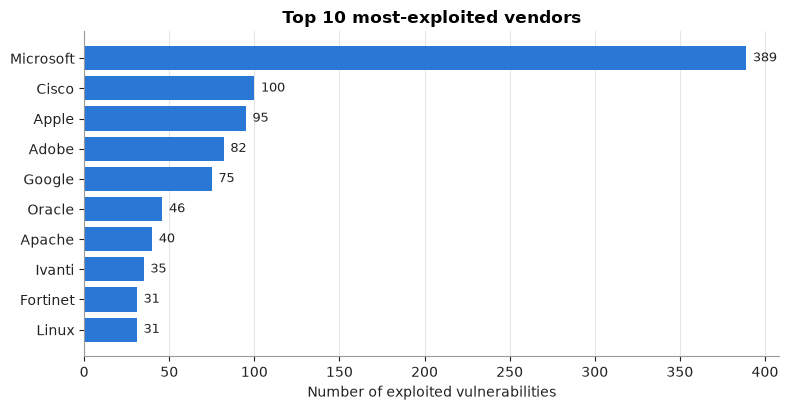

,vulnerabilities
vendorProject,
Microsoft,389
Cisco,100
Apple,95
Adobe,82
Google,75
Oracle,46
Apache,40
Ivanti,35
Fortinet,31


In [6]:
top_v = df["vendorProject"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top_v.index[::-1], top_v.values[::-1], color=BLUE)
for i, v in enumerate(top_v.values[::-1]): ax.text(v + top_v.max() * 0.01, i, str(v), va="center", color=INK, fontsize=9)
ax.set_title("Top 10 most-exploited vendors"); ax.set_xlabel("Number of exploited vulnerabilities"); ax.grid(axis="y", visible=False)
finish(fig, "02_top_vendors")
top_v.to_frame("vulnerabilities")

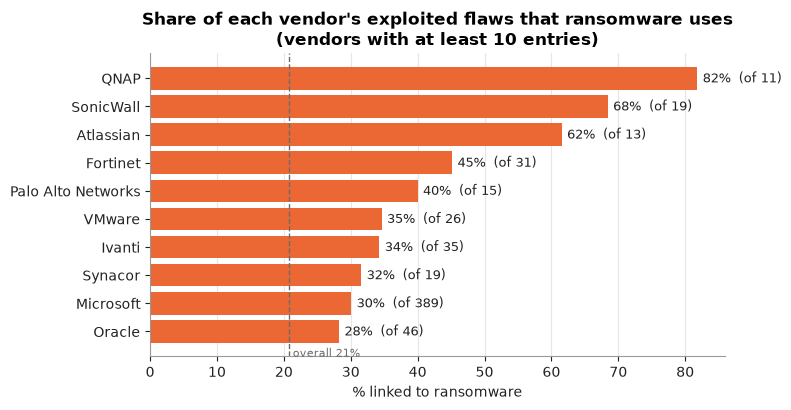

,n,ransomware,ransomware_rate
vendorProject,,,
QNAP,11,9,0.818182
SonicWall,19,13,0.684211
Atlassian,13,8,0.615385
Fortinet,31,14,0.451613
Palo Alto Networks,15,6,0.400000
VMware,26,9,0.346154
Ivanti,35,12,0.342857
Synacor,19,6,0.315789
Microsoft,389,117,0.300771


In [7]:
vend = df.groupby("vendorProject").agg(n=("ransomware", "size"), ransomware=("ransomware", "sum"))
vend["ransomware_rate"] = vend["ransomware"] / vend["n"]
big = vend[vend["n"] >= 10].sort_values("ransomware_rate", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(big.index[::-1], big["ransomware_rate"].values[::-1] * 100, color=ORANGE)
for i, (r, n) in enumerate(zip(big["ransomware_rate"].values[::-1], big["n"].values[::-1])):
    ax.text(r * 100 + 0.8, i, f"{r:.0%}  (of {n})", va="center", fontsize=9, color=INK)
ax.axvline(df["ransomware"].mean() * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(df["ransomware"].mean() * 100 + 0.5, -0.9, f"overall {df['ransomware'].mean():.0%}", color=MUTED, fontsize=8)
ax.set_title("Share of each vendor's exploited flaws that ransomware uses\n(vendors with at least 10 entries)")
ax.set_xlabel("% linked to ransomware"); ax.grid(axis="y", visible=False)
finish(fig, "03_vendor_ransomware_rate")
big[["n", "ransomware", "ransomware_rate"]]

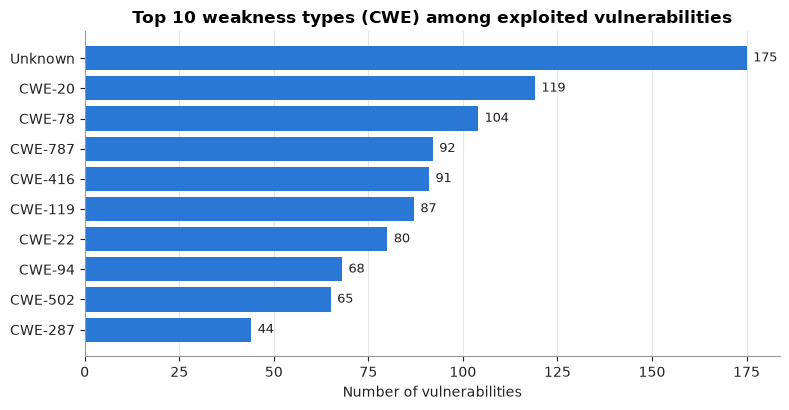

,vulnerabilities
primary_cwe,
Unknown,175
CWE-20,119
CWE-78,104
CWE-787,92
CWE-416,91
CWE-119,87
CWE-22,80
CWE-94,68
CWE-502,65


In [8]:
top_c = df["primary_cwe"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top_c.index[::-1], top_c.values[::-1], color=BLUE)
for i, v in enumerate(top_c.values[::-1]): ax.text(v + top_c.max() * 0.01, i, str(v), va="center", fontsize=9, color=INK)
ax.set_title("Top 10 weakness types (CWE) among exploited vulnerabilities")
ax.set_xlabel("Number of vulnerabilities"); ax.grid(axis="y", visible=False)
finish(fig, "04_top_cwe")
top_c.to_frame("vulnerabilities")

## Step 4: OSINT feature extraction from public text
The vulnerability descriptions are public text. We scan them for **threat signals**: what kind of attack the flaw
allows (remote code execution, authentication bypass, ...) and whether it affects the kind of product that is
usually exposed to the internet (VPNs, firewalls, gateways, ...). These become yes/no features.

In [9]:
SIGNALS = {
    "remote_code_exec":     r"remote code execution|execute arbitrary code|arbitrary code|code execution|\brce\b",
    "command_injection":    r"command injection|os command|shell command|arbitrary command",
    "auth_bypass":          r"authentication bypass|bypass authentication|improper authentication|missing authentication|unauthenticated|without authentication",
    "privilege_escalation": r"privilege escalation|elevation of privilege|escalate privileges|gain privileges",
    "sql_injection":        r"sql injection",
    "path_traversal":       r"path traversal|directory traversal",
    "deserialization":      r"deserializ",
    "memory_corruption":    r"buffer overflow|use[- ]after[- ]free|out-of-bounds|memory corruption|heap|stack-based|type confusion",
    "file_upload":          r"file upload|upload arbitrary|arbitrary file",
    "info_disclosure":      r"information disclosure|disclos|leak|sensitive information",
    "denial_of_service":    r"denial of service|denial-of-service|\bdos\b",
    "xss":                  r"cross-site scripting|\bxss\b",
}
# How dangerous each attack type is in general (our own simple judgement, 0 to 1)
IMPACT_WEIGHT = {"remote_code_exec": 1.0, "command_injection": 1.0, "auth_bypass": 0.9, "deserialization": 0.8,
                 "file_upload": 0.8, "privilege_escalation": 0.7, "sql_injection": 0.7, "memory_corruption": 0.6,
                 "path_traversal": 0.5, "info_disclosure": 0.3, "denial_of_service": 0.2, "xss": 0.2}
EXPOSED = r"\bvpn\b|firewall|gateway|router|web server|exchange|sharepoint|remote access|web interface|appliance|edge"

def add_signals(frame):
    t = (frame["text"] + " " + frame["product"]).str.lower()
    for name, pat in SIGNALS.items():
        frame[name] = t.str.contains(pat, regex=True).astype(int)
    frame["internet_facing_hint"] = t.str.contains(EXPOSED, regex=True).astype(int)
    w = np.vstack([frame[k].values * v for k, v in IMPACT_WEIGHT.items()]).max(axis=0)
    frame["impact"] = np.where(w == 0, 0.3, w)
    frame["impact"] = np.minimum(1.0, frame["impact"] + 0.15 * frame["internet_facing_hint"])
    return frame

df = add_signals(df)
SIGNAL_COLS = list(SIGNALS) + ["internet_facing_hint"]
overall = df["ransomware"].mean()
sig = pd.DataFrame({"share_of_all": df[SIGNAL_COLS].mean(),
                    "ransomware_rate_when_present": [df.loc[df[c] == 1, "ransomware"].mean() for c in SIGNAL_COLS],
                    "count": df[SIGNAL_COLS].sum()}).sort_values("ransomware_rate_when_present", ascending=False)
sig

,share_of_all,ransomware_rate_when_present,count
deserialization,0.036930,0.375000,64
sql_injection,0.018465,0.343750,32
privilege_escalation,0.133295,0.303030,231
file_upload,0.035776,0.290323,62
auth_bypass,0.207155,0.284123,359
path_traversal,0.049625,0.279070,86
internet_facing_hint,0.166763,0.249135,289
remote_code_exec,0.339296,0.231293,588
xss,0.018465,0.156250,32
command_injection,0.088863,0.149351,154


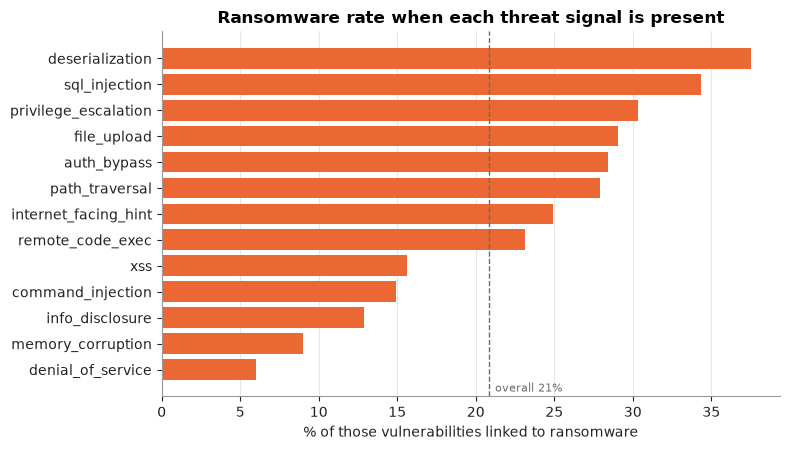

In [10]:
plot = sig[sig["count"] >= 10].sort_values("ransomware_rate_when_present")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(plot.index, plot["ransomware_rate_when_present"] * 100, color=ORANGE)
ax.axvline(overall * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(overall * 100 + 0.4, -0.85, f"overall {overall:.0%}", color=MUTED, fontsize=8)
ax.set_title("Ransomware rate when each threat signal is present")
ax.set_xlabel("% of those vulnerabilities linked to ransomware"); ax.grid(axis="y", visible=False)
finish(fig, "05_signal_ransomware_rate")

## Step 5: Train and compare machine-learning models
**Question for the model:** given what is publicly known about an exploited vulnerability (vendor, weakness type,
description text, threat signals, timing), is it linked to ransomware?

- **Text** is converted to numbers with TF-IDF (weights each word by how distinctive it is).
- **Vendor and CWE** are one-hot encoded (rare ones are grouped together).
- **Numbers and signals** are scaled.
- We compare a **baseline** (always guesses the majority class), **Logistic Regression** and **Random Forest**.
- We keep 20% of the data aside as a test set the models never see while training.

In [11]:
FEATURES = ["text", "vendorProject", "primary_cwe", "year_added", "days_to_remediate", "n_cwes"] + SIGNAL_COLS
X, y = df[FEATURES], df["ransomware"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows | ransomware share train/test: {y_train.mean():.1%} / {y_test.mean():.1%}")

def make_preprocessor():
    return ColumnTransformer([
        ("text", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_features=5000, sublinear_tf=True), "text"),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=8), ["vendorProject", "primary_cwe"]),
        ("num", StandardScaler(), ["year_added", "days_to_remediate", "n_cwes"] + SIGNAL_COLS),
    ])

def make_models():
    return {
        "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                                                random_state=SEED, n_jobs=-1),
    }
pipes = {name: Pipeline([("prep", make_preprocessor()), ("model", m)]) for name, m in make_models().items()}
for p in pipes.values(): p.fit(X_train, y_train)

rows = []
for name, p in pipes.items():
    proba = p.predict_proba(X_test)[:, 1]; pred = p.predict(X_test)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("Model")
results.round(3)

Train: 1386 rows | Test: 347 rows | ransomware share train/test: 20.9% / 20.7%


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline (majority class),0.793,0.000,0.000,0.000,0.500
Logistic Regression,0.706,0.383,0.681,0.490,0.779
Random Forest,0.801,0.537,0.306,0.389,0.756


**Reading the table:** *Accuracy* is the share of correct answers (misleading when one class is rare, which is why
the baseline can look good on it). *Precision* is how many predicted ransomware cases really are; *Recall* is how
many real ransomware cases we catch; *F1* balances the two; *ROC-AUC* measures how well the model ranks risky cases
above safe ones (0.5 = guessing, 1.0 = perfect).

A single split can be lucky or unlucky, so we also run **5-fold cross-validation** (five different train/test splits).

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name in ["Logistic Regression", "Random Forest"]:
    s = cross_validate(Pipeline([("prep", make_preprocessor()), ("model", make_models()[name])]), X, y, cv=cv,
                       scoring={"roc_auc": "roc_auc", "f1": "f1"}, n_jobs=1)
    cv_rows.append({"Model": name, "CV ROC-AUC (mean)": s["test_roc_auc"].mean(), "CV ROC-AUC (std)": s["test_roc_auc"].std(),
                    "CV F1 (mean)": s["test_f1"].mean(), "CV F1 (std)": s["test_f1"].std()})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
BEST = cv_results["CV ROC-AUC (mean)"].idxmax()
print("Best model by cross-validated ROC-AUC:", BEST)
cv_results.round(3)

Best model by cross-validated ROC-AUC: Logistic Regression


,CV ROC-AUC (mean),CV ROC-AUC (std),CV F1 (mean),CV F1 (std)
Model,,,,
Logistic Regression,0.779,0.026,0.501,0.036
Random Forest,0.775,0.031,0.398,0.031


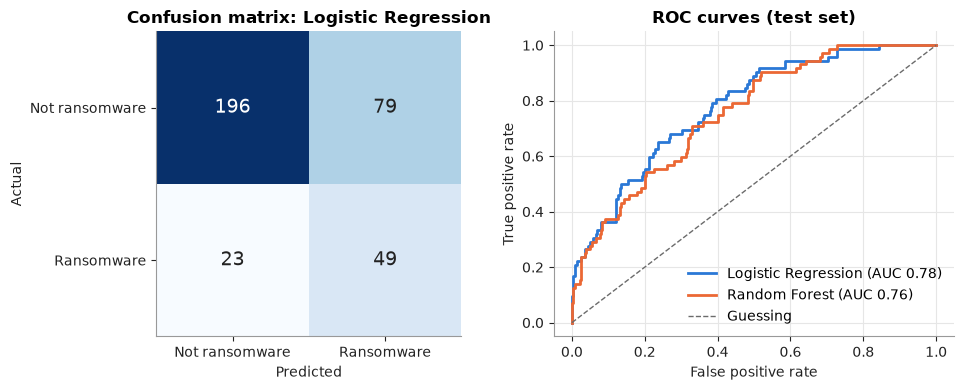

Of 72 real ransomware-linked vulnerabilities in the test set, the model caught 49 and missed 23.


In [13]:
best_pipe = pipes[BEST]
proba = best_pipe.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, best_pipe.predict(X_test))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not ransomware", "Ransomware"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Not ransomware", "Ransomware"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix: {BEST}")

ax = axes[1]
for name, colr in [("Logistic Regression", BLUE), ("Random Forest", ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, pipes[name].predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, color=colr, linewidth=2, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.2f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Guessing")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curves (test set)"); ax.legend(frameon=False, loc="lower right")
finish(fig, "06_confusion_and_roc")
print(f"Of {int(cm[1].sum())} real ransomware-linked vulnerabilities in the test set, the model caught {cm[1, 1]} and missed {cm[1, 0]}.")

## Step 6: What does the model rely on?
Logistic Regression is easy to read: each feature has a weight. Positive weights push towards "ransomware-linked",
negative weights push away. This shows which publicly visible clues matter most.

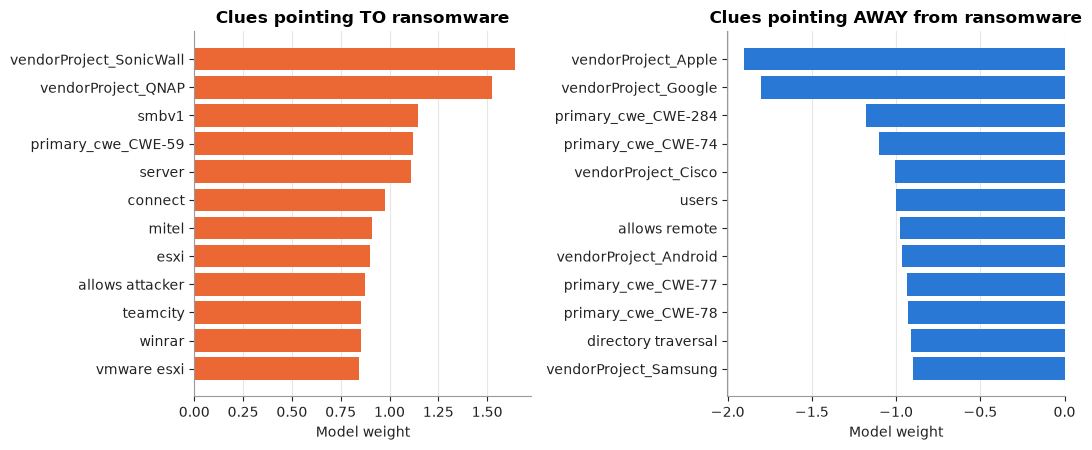

,towards ransomware,away from ransomware
0,vendorProject_SonicWall,vendorProject_Apple
1,vendorProject_QNAP,vendorProject_Google
2,smbv1,primary_cwe_CWE-284
3,primary_cwe_CWE-59,primary_cwe_CWE-74
4,server,vendorProject_Cisco
5,connect,users
6,mitel,allows remote
7,esxi,vendorProject_Android
8,allows attacker,primary_cwe_CWE-77
9,teamcity,primary_cwe_CWE-78


In [14]:
lr = pipes["Logistic Regression"]
names = [n.split("__", 1)[1] for n in lr.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=names)
top_pos, top_neg = coef.sort_values(ascending=False).head(12), coef.sort_values().head(12)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].barh(top_pos.index[::-1], top_pos.values[::-1], color=ORANGE); axes[0].set_title("Clues pointing TO ransomware")
axes[1].barh(top_neg.index[::-1], top_neg.values[::-1], color=BLUE); axes[1].set_title("Clues pointing AWAY from ransomware")
for a in axes: a.set_xlabel("Model weight"); a.grid(axis="y", visible=False)
finish(fig, "07_top_features")
pd.DataFrame({"towards ransomware": top_pos.index, "away from ransomware": top_neg.index})

## Step 7: Risk scoring
A good threat-intelligence tool gives analysts one number to prioritise by. For every vulnerability we combine:

| Component | Weight | Meaning |
|---|---|---|
| Model probability | 50% | Chance of ransomware use (from cross-validated predictions, so the model never scores data it trained on) |
| Attack impact | 25% | How dangerous the attack type is, from the signals in Step 4 |
| Vendor ransomware history | 15% | Smoothed share of the vendor's *other* exploited flaws that ransomware uses (the vulnerability's own label is left out) |
| Recency | 10% | Newer additions score higher |

**Risk score = 100 x weighted sum.** Tiers are set from the score distribution: top 10% **Critical**, next 20% **High**,
next 30% **Medium**, the rest **Low**.

In [15]:
oof = cross_val_predict(Pipeline([("prep", make_preprocessor()), ("model", make_models()[BEST])]),
                        X, y, cv=cv, method="predict_proba")[:, 1]
df["model_prob"] = oof

prior, k = df["ransomware"].mean(), 5
vstats = df.groupby("vendorProject")["ransomware"].agg(["sum", "count"])
vstats["vendor_rate"] = (vstats["sum"] + prior * k) / (vstats["count"] + k)   # used for brand-new vulnerabilities
# For vulnerabilities already in the data, leave out the row's own label so the score cannot "peek" at the answer
v_sum = df["vendorProject"].map(vstats["sum"]) - df["ransomware"]
v_cnt = df["vendorProject"].map(vstats["count"]) - 1
df["vendor_rate"] = (v_sum + prior * k) / (v_cnt + k)
span = max(1, df["year_added"].max() - df["year_added"].min())
df["recency"] = (df["year_added"] - df["year_added"].min()) / span

W = {"prob": 0.50, "impact": 0.25, "vendor": 0.15, "recency": 0.10}
df["risk_score"] = 100 * (W["prob"] * df["model_prob"] + W["impact"] * df["impact"]
                          + W["vendor"] * df["vendor_rate"] + W["recency"] * df["recency"])
q90, q70, q40 = df["risk_score"].quantile([0.90, 0.70, 0.40])
def tier(s): return "Critical" if s >= q90 else "High" if s >= q70 else "Medium" if s >= q40 else "Low"
df["risk_tier"] = df["risk_score"].apply(tier)
TIER_ORDER = ["Critical", "High", "Medium", "Low"]

print(f"Tier thresholds: Critical >= {q90:.1f}, High >= {q70:.1f}, Medium >= {q40:.1f}")
df.sort_values("risk_score", ascending=False)[["cveID", "vendorProject", "product", "risk_score", "risk_tier", "ransomware"]].head(15).round(1)

Tier thresholds: Critical >= 67.7, High >= 54.9, Medium >= 40.8


,cveID,vendorProject,product,risk_score,risk_tier,ransomware
481,CVE-2025-23006,SonicWall,SMA1000 Appliances,89.9,Critical,1
93,CVE-2026-15409,SonicWall,SMA1000 Appliances,89.5,Critical,1
44,CVE-2026-83548,SonicWall,SMA1000 Appliances,89.2,Critical,0
30,CVE-2026-19490,Citrix,NetScaler,85.2,Critical,0
253,CVE-2025-40602,SonicWall,SMA1000 appliance,83.6,Critical,0
72,CVE-2026-63077,JetBrains,TeamCity,82.2,Critical,1
670,CVE-2023-46805,Ivanti,Connect Secure and Policy Secure,81.9,Critical,1
460,CVE-2025-0108,Palo Alto Networks,PAN-OS,81.3,Critical,0
1383,CVE-2021-20038,SonicWall,SMA 100 Appliances,81.0,Critical,1
351,CVE-2025-53770,Microsoft,SharePoint,80.4,Critical,1


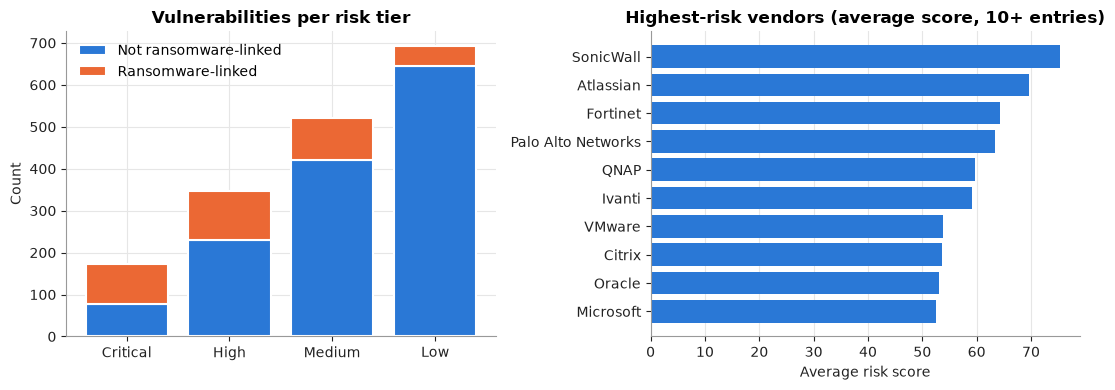

,share_actually_ransomware_linked
risk_tier,
Critical,0.557
High,0.332
Medium,0.192
Low,0.071


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tc = df.groupby(["risk_tier", "ransomware"]).size().unstack(fill_value=0).reindex(TIER_ORDER).fillna(0)
for c in [0, 1]:
    if c not in tc: tc[c] = 0
axes[0].bar(tc.index, tc[0], color=BLUE, edgecolor="white", linewidth=1.5, label="Not ransomware-linked")
axes[0].bar(tc.index, tc[1], bottom=tc[0], color=ORANGE, edgecolor="white", linewidth=1.5, label="Ransomware-linked")
axes[0].set_title("Vulnerabilities per risk tier"); axes[0].set_ylabel("Count"); axes[0].legend(frameon=False)

vr = df.groupby("vendorProject").agg(n=("risk_score", "size"), mean_risk=("risk_score", "mean"))
vr = vr[vr["n"] >= 10].sort_values("mean_risk", ascending=False).head(10)
axes[1].barh(vr.index[::-1], vr["mean_risk"].values[::-1], color=BLUE)
axes[1].set_title("Highest-risk vendors (average score, 10+ entries)"); axes[1].set_xlabel("Average risk score"); axes[1].grid(axis="y", visible=False)
finish(fig, "08_risk_tiers_and_vendors")
share = df.groupby("risk_tier")["ransomware"].mean().reindex(TIER_ORDER)
share.to_frame("share_actually_ransomware_linked").round(3)

If the scoring works, the **Critical** tier should contain a much higher share of truly ransomware-linked
vulnerabilities than the **Low** tier. The table above checks exactly that.

## Step 8: The CyberIntel analyser (try a new vulnerability)
Type a public vulnerability description and the tool returns the predicted ransomware likelihood, an estimated
risk score and a tier. The two examples below are **made-up illustrations**, not real CVEs.

In [17]:
final_model = Pipeline([("prep", make_preprocessor()), ("model", make_models()[BEST])]).fit(X, y)

def analyse(description, vendor="Unknown", product="", year=None):
    row = pd.DataFrame([{"text": description, "product": product, "vendorProject": vendor, "primary_cwe": "Unknown",
                         "year_added": year or int(df["year_added"].max()),
                         "days_to_remediate": float(df["days_to_remediate"].median()), "n_cwes": 1}])
    row = add_signals(row)
    p = float(final_model.predict_proba(row[FEATURES])[0, 1])
    v_rate = float(vstats["vendor_rate"].get(vendor, prior))
    rec = (row["year_added"].iloc[0] - df["year_added"].min()) / span
    score = 100 * (W["prob"] * p + W["impact"] * row["impact"].iloc[0] + W["vendor"] * v_rate + W["recency"] * rec)
    found = [k for k in SIGNAL_COLS if row[k].iloc[0] == 1]
    return {"ransomware_likelihood": round(p, 3), "risk_score": round(float(score), 1), "tier": tier(score), "signals_found": found}

examples = [
    "A remote code execution vulnerability in a VPN gateway allows an unauthenticated attacker to execute arbitrary commands.",
    "A cross-site scripting flaw in a desktop photo viewer may display attacker-controlled text.",
]
for text in examples:
    print(text); print("  ->", analyse(text), "\n")

A remote code execution vulnerability in a VPN gateway allows an unauthenticated attacker to execute arbitrary commands.
  -> {'ransomware_likelihood': 0.52, 'risk_score': 64.1, 'tier': 'High', 'signals_found': ['remote_code_exec', 'command_injection', 'auth_bypass', 'internet_facing_hint']} 

A cross-site scripting flaw in a desktop photo viewer may display attacker-controlled text.
  -> {'ransomware_likelihood': 0.203, 'risk_score': 28.3, 'tier': 'Low', 'signals_found': ['xss']} 



## Step 9: Save results and summarise

In [18]:
results.round(4).to_csv(OUT / "model_comparison.csv")
cv_results.round(4).to_csv(OUT / "cross_validation.csv")
df.sort_values("risk_score", ascending=False)[["cveID", "vendorProject", "product", "vulnerabilityName", "dateAdded",
    "primary_cwe", "ransomware", "model_prob", "risk_score", "risk_tier"]].round(3).to_csv(OUT / "risk_scored_vulnerabilities.csv", index=False)

metrics = {
    "n_rows": int(len(df)), "date_min": str(df["dateAdded"].min().date()), "date_max": str(df["dateAdded"].max().date()),
    "n_vendors": int(df["vendorProject"].nunique()), "n_ransomware": int(df["ransomware"].sum()),
    "ransomware_share": float(df["ransomware"].mean()), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "best_model": BEST, "test_results": results.round(4).reset_index().to_dict("records"),
    "cv_results": cv_results.round(4).reset_index().to_dict("records"),
    "confusion_matrix": cm.tolist(),
    "per_year": {str(int(k)): int(v) for k, v in df["year_added"].value_counts().sort_index().items()},
    "top_vendors": {k: int(v) for k, v in df["vendorProject"].value_counts().head(10).items()},
    "top_cwe": {k: int(v) for k, v in df["primary_cwe"].value_counts().head(10).items()},
    "vendor_ransomware_rate": {k: [round(float(r.ransomware_rate), 3), int(r.n)] for k, r in big.iterrows()},
    "signals": {k: [round(float(r.ransomware_rate_when_present), 3), int(r["count"])] for k, r in sig.iterrows() if r["count"] >= 10},
    "tier_thresholds": {"critical": float(q90), "high": float(q70), "medium": float(q40)},
    "tier_share_ransomware": {k: round(float(v), 3) for k, v in share.items()},
    "tier_counts": {k: int(v) for k, v in df["risk_tier"].value_counts().reindex(TIER_ORDER).items()},
    "top_positive_clues": list(top_pos.index), "top_negative_clues": list(top_neg.index),
    "top_risk": df.sort_values("risk_score", ascending=False).head(10)[["cveID", "vendorProject", "product", "risk_score", "risk_tier", "ransomware"]].round(1).to_dict("records"),
    "mean_days_to_remediate": float(df["days_to_remediate"].mean()),
    "median_days_to_remediate": float(df["days_to_remediate"].median()),
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))

b = results.loc[BEST]
print("KEY FINDINGS")
print(f"- {metrics['n_rows']} actively exploited vulnerabilities from {metrics['n_vendors']} vendors; {metrics['ransomware_share']:.1%} are linked to ransomware.")
print(f"- Best model: {BEST} (test ROC-AUC {b['ROC-AUC']:.3f}, F1 {b['F1']:.3f}, recall {b['Recall']:.3f}, precision {b['Precision']:.3f}).")
print(f"- Share truly ransomware-linked by tier: " + ", ".join(f"{t} {v:.0%}" for t, v in share.items()))
print("Files saved in the 'outputs' folder.")

KEY FINDINGS
- 1733 actively exploited vulnerabilities from 284 vendors; 20.8% are linked to ransomware.
- Best model: Logistic Regression (test ROC-AUC 0.779, F1 0.490, recall 0.681, precision 0.383).
- Share truly ransomware-linked by tier: Critical 56%, High 33%, Medium 19%, Low 7%
Files saved in the 'outputs' folder.


## Limitations and future work
- The catalog only lists vulnerabilities that were **confirmed exploited**, so it is not a sample of all vulnerabilities.
- The ransomware label can change over time as new campaigns are reported, so some "Unknown" entries may become "Known".
- The risk weights are our own reasoned choices and should be tuned with an organisation's real priorities.
- Future work: add CVSS and EPSS scores from the NVD and FIRST, add public threat feeds (phishing URLs, malicious IPs),
  and build a small dashboard that refreshes automatically.